# Chapitre 2 - Cours 1 : Données d'entraînement et architecture transformer

Pourquoi deux modèles de fondation de même taille se comportent-ils si différemment ?
Le chapitre 2 du livre ramène ces différences à quelques **décisions de conception** :
les données d'entraînement, l'architecture et la taille du modèle, le post-entraînement,
et enfin la manière d'**échantillonner** les sorties. Ce premier notebook traite les deux
premières :

- section *Training Data* (avec *Multilingual Models* et *Domain-Specific Models*) :
  d'où viennent les données, qui y est représenté, et ce que cela coûte en tokens ;
- section *Model Architecture*, sous-section *Transformer architecture* : du seq2seq au
  transformer, le mécanisme d'attention (que l'on code à la main en numpy puis que l'on
  confronte aux vrais GPT-2 et Qwen2.5), les cartes d'attention réelles et le bloc
  transformer.

**Plan.** 1. Un modèle ne vaut que ses données ; 2. Qui est représenté dans le web ?
3. Le coût caché des langues ; 4. Modèles spécialisés ; 5. Du seq2seq au transformer ;
6. L'attention pas à pas ; 7. Multi-têtes : vérification sur GPT-2 et Qwen2.5 ;
8. Ce que regardent les têtes ; 9. Le bloc transformer ; Synthèse.

Tous les calculs de ce notebook tournent sur CPU (GPT-2 et Qwen2.5-0.5B en float32).

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tiktoken
import torch
from transformers import AutoTokenizer

from aie import llm
from aie import ch02_modeles as m
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
rng = np.random.default_rng(0)
torch.set_num_threads(8)
pd.set_option("display.precision", 2)

## 1. Un modèle ne vaut que ses données (section *Training Data*)

Un modèle n'apprend que ce qu'il voit : sans vietnamien dans ses données, il ne
traduira pas vers le vietnamien. Or réunir des données pour un modèle de plusieurs
milliards de paramètres coûte cher, si bien que les développeurs utilisent surtout ce
qui est **disponible** plutôt que ce qui serait **idéal**. La source dominante est
**Common Crawl**, une association qui explore le web (de l'ordre de 2 à 3 milliards de
pages par mois en 2022-2023), et sa version nettoyée par Google, **C4**. Leur qualité
est inégale : désinformation, pièges à clics, contenus haineux y côtoient Wikipédia.

D'où des **filtres heuristiques** (GPT-2 n'a gardé que les liens Reddit ayant reçu au
moins trois votes positifs), puis, de plus en plus, une **curation** ciblée par langue
ou par domaine. Plus de données n'est pas toujours mieux : le livre cite un modèle de
1,3 milliard de paramètres entraîné sur seulement 7 milliards de tokens de code de haute
qualité qui dépasse des modèles bien plus gros (Gunasekar et al., 2023). Le chapitre 8
reviendra sur l'ingénierie des données ; le schéma ci-dessous situe les étapes.

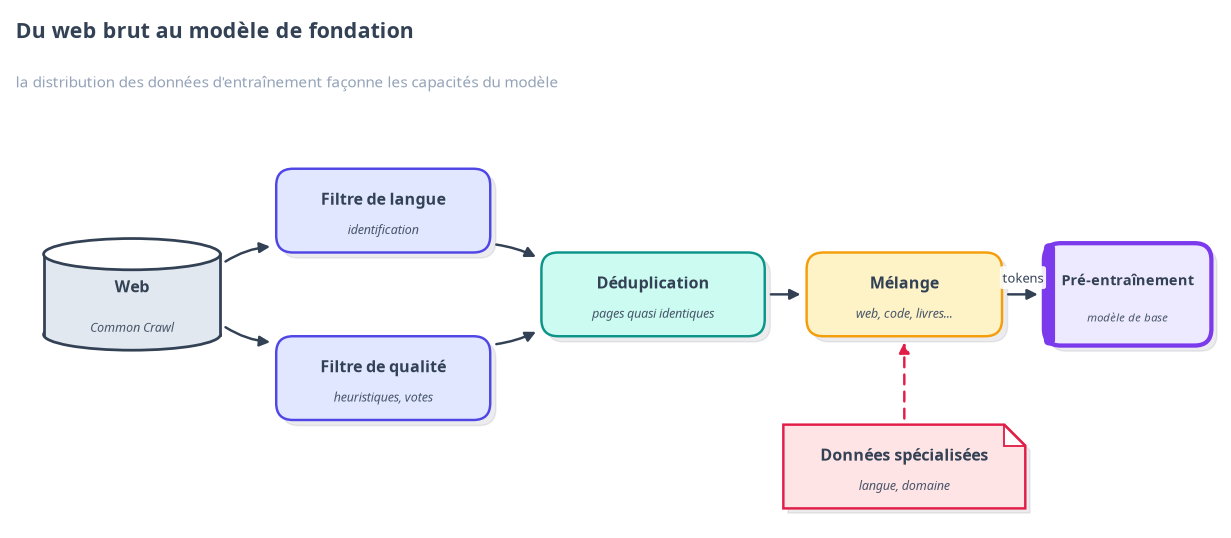

In [2]:
d = Diagram(13, 4.6, title="Du web brut au modèle de fondation",
            subtitle="la distribution des données d'entraînement façonne les capacités du modèle")
d.box("web", 1.3, 2.5, "Web", sub="Common Crawl", color=SLATE, kind="db", w=1.9, h=1.2)
d.box("lang", 4.0, 3.4, "Filtre de langue", sub="identification", color=INDIGO, w=2.3)
d.box("qual", 4.0, 1.6, "Filtre de qualité", sub="heuristiques, votes", color=INDIGO, w=2.3)
d.box("dedup", 6.9, 2.5, "Déduplication", sub="pages quasi identiques", color=TEAL, w=2.4)
d.box("mix", 9.6, 2.5, "Mélange", sub="web, code, livres...", color=AMBER, w=2.1)
d.box("spec", 9.6, 0.65, "Données spécialisées", sub="langue, domaine", color=ROSE, kind="doc", w=2.6, h=0.9)
d.box("model", 12.0, 2.5, "Pré-entraînement", sub="modèle de base", color=VIOLET, kind="model", w=1.8, h=1.1,
      fontsize=9.5)
d.arrow("web", "lang", rad=-0.15)
d.arrow("web", "qual", rad=0.15)
d.arrow("lang", "dedup", rad=-0.1)
d.arrow("qual", "dedup", rad=0.1)
d.arrow("dedup", "mix")
d.arrow("spec", "mix", style="dashed", color=ROSE)
d.arrow("mix", "model", "tokens")
d.show()

> **À retenir.** Les capacités d'un modèle reflètent la distribution de ses données :
> ce qui est rare ou absent du corpus (une langue, un domaine, une tâche) sera mal
> maîtrisé, quelle que soit la taille du modèle.

## 2. Modèles multilingues : qui est représenté dans le web ? (section *Multilingual Models*)

L'anglais représente près de **46 %** de Common Crawl, huit fois plus que la deuxième
langue (le russe, 6 %). Le livre compare la part de chaque langue dans la population
mondiale à sa part dans Common Crawl ; si l'on note $\pi_\ell$ la part des locuteurs de
la langue $\ell$ et $c_\ell$ sa part du corpus, le ratio
$$\rho_\ell = \frac{\pi_\ell}{c_\ell}$$
vaudrait 1 pour une représentation « équitable ». Un ratio de 100 signifie que la langue
est cent fois moins présente dans le corpus que dans le monde. Les langues absentes de la
liste des langues à plus de 1 % sont dites **peu dotées** (*low-resource*).

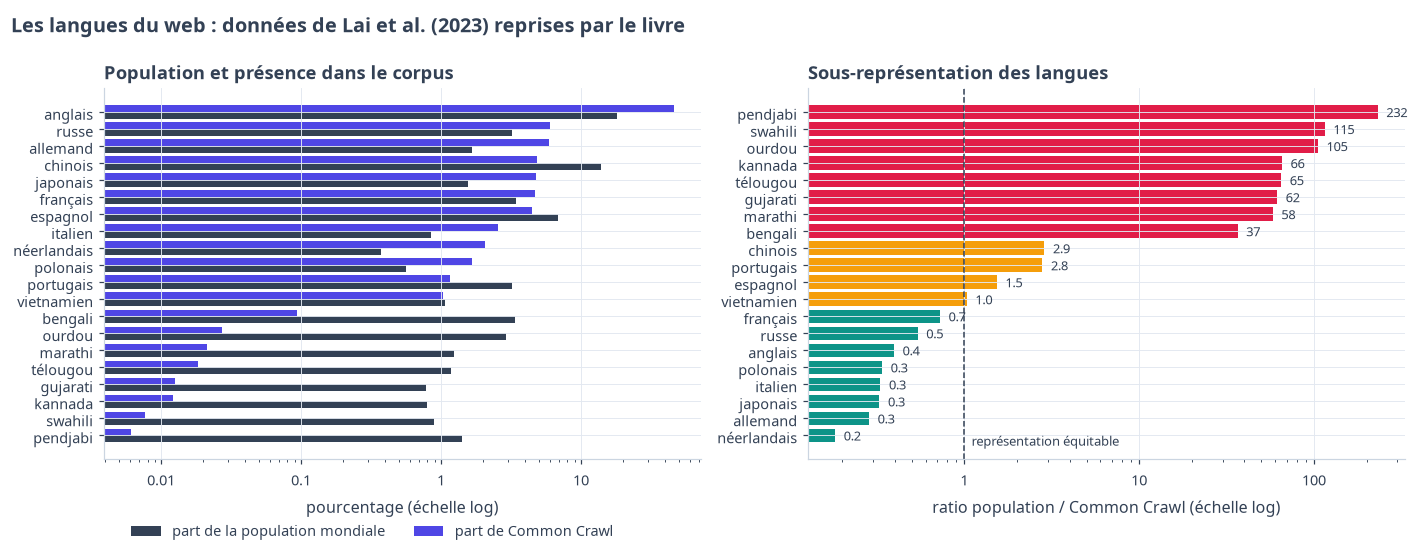

In [3]:
cc = m.common_crawl_table()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
y = np.arange(len(cc))
ax.barh(y + 0.2, cc["pop_pct"], height=0.4, color=SLATE, label="part de la population mondiale")
ax.barh(y - 0.2, cc["cc_pct"], height=0.4, color=INDIGO, label="part de Common Crawl")
ax.set_yticks(y, cc["langue"]); ax.invert_yaxis(); ax.set_xscale("log")
ax.set_xlabel("pourcentage (échelle log)"); m.plain_log_axis(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=2)
ax.set_title("Population et présence dans le corpus")
ax = axes[1]
srt = cc.sort_values("ratio_pop_cc")
colors = [TEAL if r < 1 else (AMBER if r < 10 else ROSE) for r in srt["ratio_pop_cc"]]
ax.barh(srt["langue"], srt["ratio_pop_cc"], color=colors)
ax.axvline(1, color=SLATE, ls="--", lw=1); ax.set_xscale("log")
ax.text(1.1, -0.6, "représentation équitable", fontsize=8.5, color=SLATE)
for yy, r in enumerate(srt["ratio_pop_cc"]):
    ax.text(r * 1.12, yy, f"{r:.1f}" if r < 10 else f"{r:.0f}", va="center", fontsize=8.5)
ax.set_xlabel("ratio population / Common Crawl (échelle log)"); m.plain_log_axis(ax)
ax.set_title("Sous-représentation des langues")
finish(fig, "Les langues du web : données de Lai et al. (2023) reprises par le livre")
plt.show()

Le pendjabi (113 millions de locuteurs) est plus de 200 fois sous-représenté, et les
langues les moins représentées (télougou, marathi, pendjabi) sont précisément celles où
GPT-4 obtient ses plus mauvais scores sur MMLU d'après le livre. La sous-représentation
n'explique pas tout (la structure d'une langue et la culture qu'elle porte jouent aussi),
et **traduire vers l'anglais** n'est pas une solution miracle : il faut un modèle qui
comprenne déjà la langue source, et la traduction perd de l'information (les pronoms
vietnamiens encodent la relation entre interlocuteurs, que « I » et « you » écrasent).

> **À retenir.** Le français est plutôt bien loti (4,7 % de Common Crawl, ratio proche
> de 1), mais des langues parlées par des centaines de millions de personnes sont
> quasiment absentes des corpus : un modèle généraliste y sera nettement moins bon.

## 3. Le coût caché des langues : tokens par langue

Au-delà de la qualité, le livre souligne un effet très concret : la **latence** et le
**coût** d'une requête sont proportionnels au nombre de tokens, et ce nombre dépend de
la langue. Sur le jeu de données MASSIVE, la longueur médiane d'un même énoncé est de 7
tokens en anglais, 32 en hindi et 72 en birman avec le tokenizer de GPT-4.

Mesurons-le nous-mêmes sur un petit **corpus parallèle** rédigé pour ce cours : les six
mêmes phrases dans 18 langues (`m.PARALLEL_CORPUS`), découpées par quatre tokenizers :

| tokenizer | modèle | vocabulaire |
|---|---|---|
| `gpt2` | GPT-2 (2019) | 50 257 |
| `cl100k_base` | GPT-4 | 100 277 |
| `o200k_base` | GPT-4o | 200 019 |
| Qwen2.5 | Qwen2.5 (2024) | 151 665 |

Pour chaque langue $\ell$ et chaque tokenizer, on calcule le **ratio de fertilité**
$r_\ell = n_\ell / n_{\text{en}}$ : le nombre de tokens pour dire la même chose, rapporté
à l'anglais.

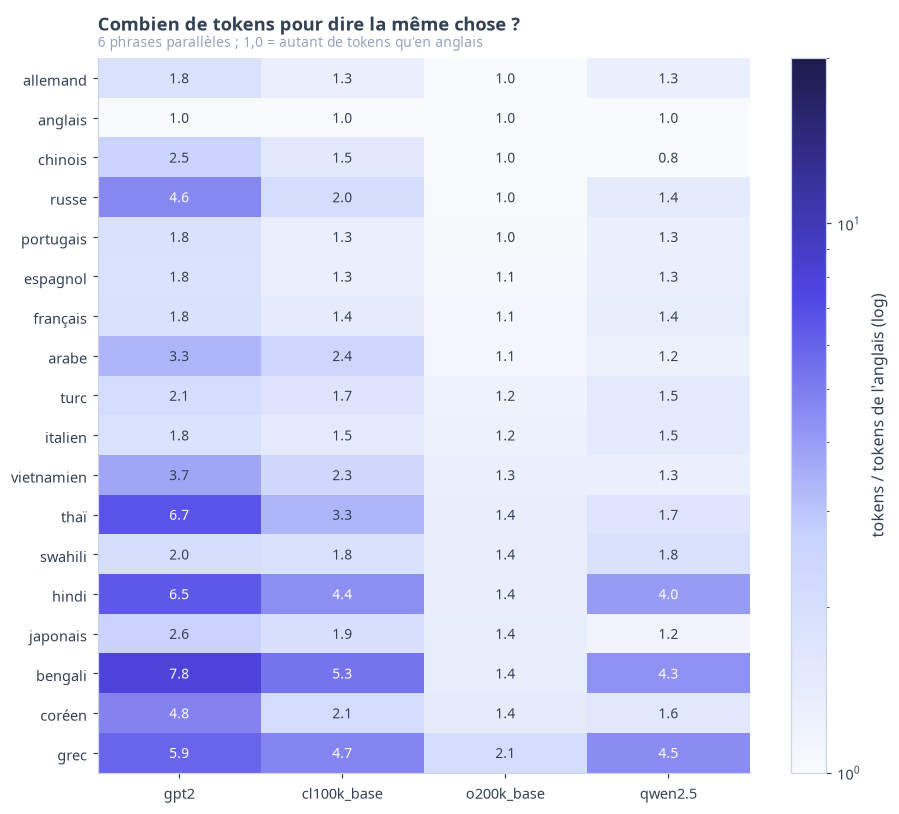

In [4]:
qwen_tok = AutoTokenizer.from_pretrained(llm.SMALL)
encoders = {name: tiktoken.get_encoding(name).encode for name in ["gpt2", "cl100k_base", "o200k_base"]}
encoders["qwen2.5"] = lambda s: qwen_tok(s, add_special_tokens=False)["input_ids"]
fert = m.tokens_per_language(encoders)
pivot = fert.pivot(index="langue", columns="tokenizer", values="ratio_vs_en")
pivot = pivot[["gpt2", "cl100k_base", "o200k_base", "qwen2.5"]].sort_values("o200k_base")

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(pivot.values, cmap="aie_seq", aspect="auto", norm=plt.matplotlib.colors.LogNorm(1, 20))
ax.set_xticks(range(4), pivot.columns); ax.set_yticks(range(len(pivot)), pivot.index)
ax.grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9,
                color="white" if v > 4 else SLATE)
plt.colorbar(im, ax=ax, label="tokens / tokens de l'anglais (log)")
ax.set_title("Combien de tokens pour dire la même chose ?", pad=18)
subtitle(ax, "6 phrases parallèles ; 1,0 = autant de tokens qu'en anglais")
plt.tight_layout(); plt.show()

Trois constats :

1. **Le tokenizer de GPT-2** (entraîné sur un web anglophone) est très inefficace hors de
   l'alphabet latin : une phrase en hindi, bengali ou thaï coûte 6 à 8 fois plus de
   tokens qu'en anglais (le livre rapporte jusqu'à 10 fois pour le birman avec GPT-4). La raison est mécanique : ce tokenizer travaille sur les
   **octets** UTF-8 ; un caractère devanagari occupe 3 octets, et faute de fusions
   apprises pour ces séquences, chaque octet devient presque un token.
2. **Les vocabulaires plus grands et plus multilingues** réduisent l'écart, mais pas
   uniformément : `o200k_base` (GPT-4o) ramène presque toutes nos langues sous 1,5,
   tandis que Qwen2.5, très efficace en chinois (0,8 : moins de tokens qu'en anglais !),
   reste à environ 4 pour le hindi, le bengali et le grec. Un tokenizer reflète les
   priorités linguistiques de ses concepteurs.
3. Le **français** coûte de 10 % (`o200k_base`) à 80 % (GPT-2) de tokens de plus que
   l'anglais : la pénalité existe même pour une langue bien dotée.

Vérifions l'explication par les octets : nombre moyen d'octets UTF-8 par caractère et de
tokens GPT-2 par caractère, selon l'écriture.

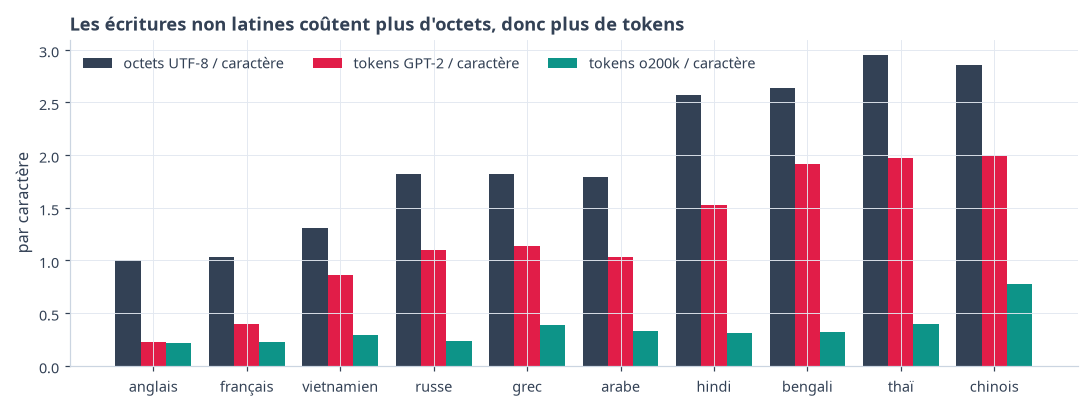

In [5]:
gpt2_enc = encoders["gpt2"]
rows = []
for code in ["en", "fr", "vi", "ru", "el", "ar", "hi", "bn", "th", "zh"]:
    txt = " ".join(m.PARALLEL_CORPUS[code])
    rows.append(dict(langue=m.LANG_NAMES[code], octets_par_car=len(txt.encode()) / len(txt),
                     tokens_gpt2_par_car=len(gpt2_enc(txt)) / len(txt),
                     tokens_o200k_par_car=len(encoders["o200k_base"](txt)) / len(txt)))
bytes_df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(bytes_df))
ax.bar(x - 0.27, bytes_df.octets_par_car, 0.27, color=SLATE, label="octets UTF-8 / caractère")
ax.bar(x, bytes_df.tokens_gpt2_par_car, 0.27, color=ROSE, label="tokens GPT-2 / caractère")
ax.bar(x + 0.27, bytes_df.tokens_o200k_par_car, 0.27, color=TEAL, label="tokens o200k / caractère")
ax.set_xticks(x, bytes_df.langue); ax.set_ylabel("par caractère")
ax.set_title("Les écritures non latines coûtent plus d'octets, donc plus de tokens")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

Le nombre de tokens GPT-2 par caractère suit de près le nombre d'octets par caractère :
pour les écritures que son vocabulaire n'a pas « vues », le tokenizer retombe presque
au niveau de l'octet.

**Traduisons en coût et en latence.** Supposons une application qui traite chaque jour
100 000 requêtes de 500 tokens (comptés en anglais) à 2,50 \$ par million de tokens en
entrée, et qui génère des réponses de 300 tokens à 50 tokens par seconde. Avec le ratio
$r_\ell$ mesuré pour le tokenizer de Qwen2.5 (le modèle ouvert utilisé dans ce cours) :
$$\text{coût}_\ell = r_\ell \times \text{coût}_{\text{en}}, \qquad
\text{latence}_\ell \approx r_\ell \times \frac{300}{50}\ \text{s}.$$

In [6]:
sel = ["chinois", "anglais", "espagnol", "français", "arabe", "vietnamien", "hindi", "bengali", "grec"]
rq = fert[fert.tokenizer == "qwen2.5"].set_index("langue")["ratio_vs_en"].loc[sel]
cost_en = 100_000 * 500 / 1e6 * 2.50
tab = pd.DataFrame({"ratio de tokens": rq, "coût entrée / jour ($)": rq * cost_en,
                    "latence réponse (s)": rq * 300 / 50,
                    "contexte 8k utile (équiv. tokens anglais)": 8192 / rq})
tab.round(1)

,ratio de tokens,coût entrée / jour ($),latence réponse (s),contexte 8k utile (équiv. tokens anglais)
langue,,,,
chinois,0.8,96.2,4.6,10649.6
anglais,1.0,125.0,6.0,8192.0
espagnol,1.3,163.5,7.8,6264.5
français,1.4,173.1,8.3,5916.4
arabe,1.2,156.2,7.5,6553.6
vietnamien,1.3,161.1,7.7,6358.0
hindi,4.0,502.4,24.1,2038.2
bengali,4.3,543.3,26.1,1884.9
grec,4.5,557.7,26.8,1836.1


Pour le même service, une langue à ratio 4 coûte quatre fois plus cher, répond quatre
fois plus lentement et « voit » quatre fois moins de contenu dans la même fenêtre de
contexte ; plus généralement, une langue à ratio 2 coûte deux fois plus cher, répond deux fois
plus lentement et « voit » deux fois moins de contenu dans la même fenêtre de contexte.
C'est l'une des raisons pour lesquelles on entraîne des modèles centrés sur une langue
(le livre cite CroissantLLM pour le français, PhoGPT pour le vietnamien, Jais pour
l'arabe), avec un tokenizer adapté.

> **À retenir.** Le nombre de tokens pour un même contenu varie d'un facteur 1 à plus
> de 10 selon la langue et le tokenizer. Coût, latence et contexte utile en dépendent
> directement : mesurez-le sur vos propres données avant de choisir un modèle.

## 4. Modèles spécialisés : la distribution des domaines (section *Domain-Specific Models*)

Les modèles généralistes sont bons en code, droit ou sciences parce que ces domaines
sont présents dans le web. Mais des tâches comme la découverte de médicaments (séquences
de protéines, d'ADN) ou le dépistage du cancer (imagerie médicale) reposent sur des
données rares, chères ou privées, absentes des corpus publics. D'où des modèles
spécialisés : AlphaFold (environ 100 000 structures de protéines), BioNeMo, Med-PaLM 2.

On peut **mesurer** à quel point un modèle est « chez lui » dans un domaine avec sa
perte de modélisation : un texte bien représenté dans les données d'entraînement est
mieux prédit. Pour comparer équitablement des tokenizers différents, on utilise les
**bits par caractère** plutôt que la perplexité par token :
$$\text{bpc} = \frac{1}{n_{\text{car}}}\sum_{t} -\log_2 p(x_t \mid x_{<t}).$$
(Le chapitre 3 détaillera entropie, perplexité et bits par caractère.) On compare GPT-2
(2019, web anglophone filtré par Reddit) et Qwen2.5-0.5B (2024, 18 000 milliards de
tokens multilingues, riches en code et en mathématiques).

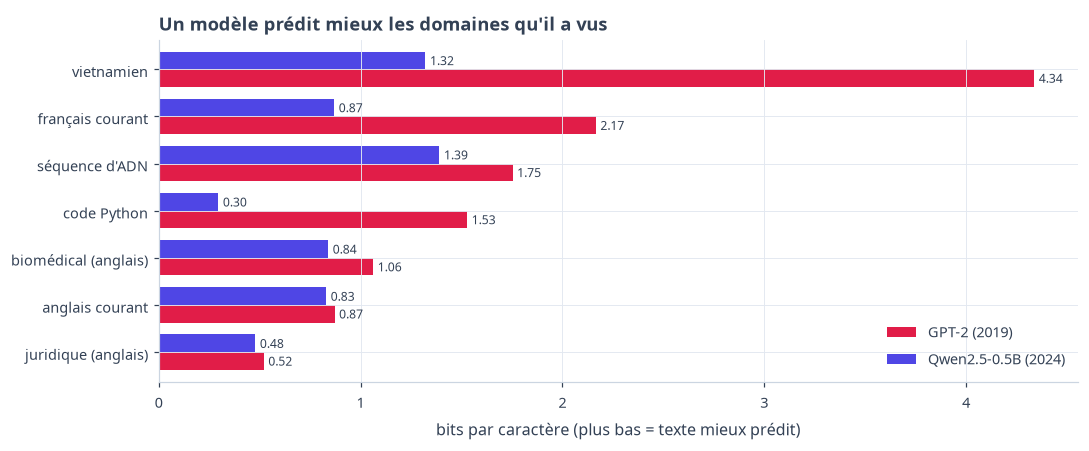

In [7]:
DOMAIN_TEXTS = {
    "anglais courant": "The city council met on Tuesday evening to discuss the new public library. "
                       "Several residents asked for longer opening hours on weekends, and the mayor "
                       "promised to present a budget proposal next month.",
    "français courant": "Le conseil municipal s'est réuni mardi soir pour discuter de la nouvelle "
                        "bibliothèque. Plusieurs habitants ont demandé des horaires plus larges le "
                        "week-end, et le maire a promis de présenter un budget le mois prochain.",
    "code Python": "def moving_average(values, window):\n    if window <= 0:\n        raise ValueError"
                   "('window must be positive')\n    out = []\n    for i in range(len(values) - window + 1):"
                   "\n        out.append(sum(values[i:i + window]) / window)\n    return out\n",
    "juridique (anglais)": "The Licensee shall indemnify and hold harmless the Licensor from any claims, "
                           "damages or liabilities arising out of the use of the Software, except to the "
                           "extent caused by the gross negligence of the Licensor.",
    "biomédical (anglais)": "Patients receiving pembrolizumab showed improved progression-free survival "
                            "compared with docetaxel, with grade 3 immune-related adverse events, notably "
                            "pneumonitis and colitis, reported in 9% of the cohort.",
    "vietnamien": "Hội đồng thành phố đã họp vào tối thứ Ba để thảo luận về thư viện công cộng mới. "
                  "Nhiều người dân đề nghị mở cửa lâu hơn vào cuối tuần.",
    "séquence d'ADN": "ATGGCGTACGCTAGCTAGGCTTACGATCGATCGGCTAGCTAGCATCGATCGTACGATCGTAGCTAGCTAGGCTAGCTAACG"
                      "TAGCTAGCTAGCATGCATCGATCGATGCTAGCTAGCTAGCATCGATCGATCGTAGCTAGCTA",
}


def bits_per_char(text, model_id):
    tok, model = m.load_eager(model_id)
    ids = tok(text, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        lp = torch.log_softmax(model(ids).logits[0, :-1].float(), -1)
    nll = -lp[torch.arange(ids.shape[1] - 1), ids[0, 1:]].sum().item()
    first = tok.decode(ids[0, :1])  # le premier token n'est pas prédit : on retire ses caractères
    return nll / np.log(2) / max(len(text) - len(first), 1)


bpc = pd.DataFrame({name: {dom: bits_per_char(t, mid) for dom, t in DOMAIN_TEXTS.items()}
                    for name, mid in [("GPT-2 (2019)", "gpt2"), ("Qwen2.5-0.5B (2024)", llm.SMALL)]})
fig, ax = plt.subplots(figsize=(10, 4.2))
bpc.sort_values("GPT-2 (2019)").plot.barh(ax=ax, color=[ROSE, INDIGO], width=0.75)
annotate_bars(ax, "{:.2f}", fontsize=8)
ax.set_xlabel("bits par caractère (plus bas = texte mieux prédit)")
ax.set_title("Un modèle prédit mieux les domaines qu'il a vus")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Lecture de la figure :

- les deux modèles sont à l'aise sur l'anglais courant ; GPT-2 l'est beaucoup moins sur
  le français et surtout sur le vietnamien, quasi absent de ses données, alors que
  Qwen2.5, entraîné sur un corpus multilingue, réduit fortement l'écart ;
- le **code** est bien mieux prédit par Qwen2.5, dont le corpus est riche en code ;
- pour GPT-2, le jargon biomédical coûte plus cher que l'anglais courant ; Qwen2.5, au
  corpus plus vaste et plus scientifique, le prédit presque aussi bien. Les formules
  juridiques, très stéréotypées et omniprésentes sur le web (licences, conditions
  d'utilisation), sont au contraire les plus faciles à prédire ;
- la séquence d'ADN est un cas à part : son alphabet de 4 lettres borne l'entropie à
  2 bits par caractère, mais un modèle de langue généraliste n'en saisit pas la
  « grammaire » biologique, d'où les modèles dédiés.

> **À retenir.** Pour une tâche spécialisée, vérifiez d'abord que le domaine est couvert
> par les données du modèle ; la perte (ou les bits par caractère) sur un échantillon de
> vos textes est un premier diagnostic peu coûteux.

## 5. Du seq2seq au transformer (section *Transformer architecture*)

Le transformer (Vaswani et al., 2017) répond à deux défauts de l'architecture
**seq2seq** à base de RNN qui dominait la traduction automatique depuis 2014 :

1. **Le goulot d'information.** Le décodeur ne voit l'entrée qu'à travers le **dernier
   état caché** de l'encodeur : c'est, dit le livre, comme répondre à des questions sur
   un livre à partir de son seul résumé.
2. **La séquentialité.** Un RNN traite les tokens un par un : $h_t = f(h_{t-1}, x_t)$.
   Impossible de paralléliser sur la longueur de la séquence, et les gradients doivent
   traverser $T$ étapes (évanescence ou explosion).

Le mécanisme d'**attention** permet au contraire, pour chaque token produit, de consulter
directement n'importe quel token de l'entrée (n'importe quelle page du livre), et le
transformer se débarrasse entièrement des RNN.

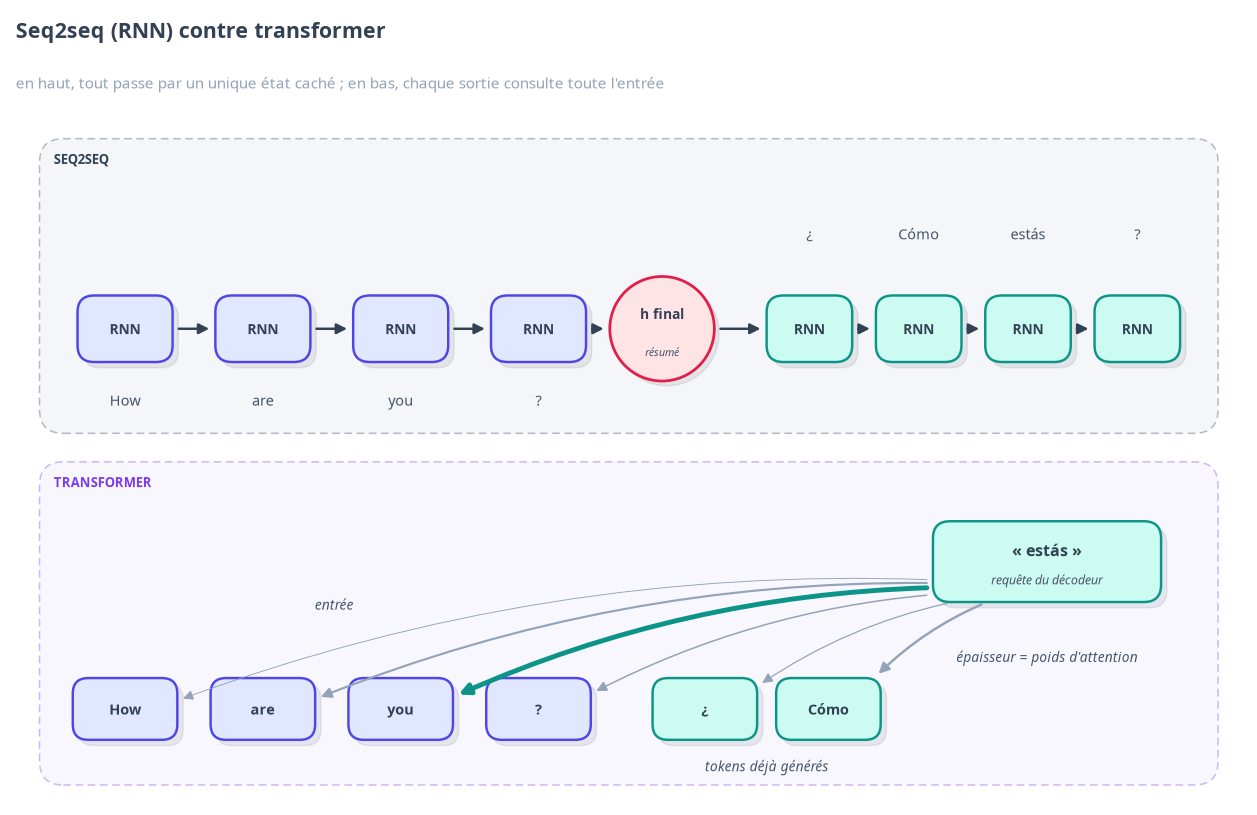

In [8]:
d = Diagram(13, 7.4, title="Seq2seq (RNN) contre transformer",
            subtitle="en haut, tout passe par un unique état caché ; en bas, chaque sortie consulte toute l'entrée")
src = ["How", "are", "you", "?"]
out = ["¿", "Cómo", "estás", "?"]
# seq2seq
d.group(0.3, 3.9, 12.7, 7.0, "seq2seq", color=SLATE)
for i, w in enumerate(src):
    d.box(f"e{i}", 1.2 + 1.45 * i, 5.0, "RNN", color=INDIGO, w=1.0, h=0.7, fontsize=9)
    d.note(1.2 + 1.45 * i, 4.25, w, fontsize=9.5, style="normal")
for i in range(3):
    d.arrow(f"e{i}", f"e{i + 1}")
d.box("ctx", 6.85, 5.0, "h final", sub="résumé", color=ROSE, kind="circle", w=1.1, fontsize=9)
d.arrow("e3", "ctx")
for i, w in enumerate(out):
    d.box(f"d{i}", 8.4 + 1.15 * i, 5.0, "RNN", color=TEAL, w=0.9, h=0.7, fontsize=9)
    d.note(8.4 + 1.15 * i, 6.0, w, fontsize=9.5, style="normal")
d.arrow("ctx", "d0")
for i in range(3):
    d.arrow(f"d{i}", f"d{i + 1}")
# transformer
d.group(0.3, 0.2, 12.7, 3.6, "transformer", color=VIOLET)
for i, w in enumerate(src):
    d.box(f"t{i}", 1.2 + 1.45 * i, 1.0, w, color=INDIGO, w=1.1, h=0.65, fontsize=9.5)
for i, w in enumerate(["¿", "Cómo"]):
    d.box(f"g{i}", 7.3 + 1.3 * i, 1.0, w, color=TEAL, w=1.1, h=0.65, fontsize=9.5)
d.box("q", 10.9, 2.55, "« estás »", sub="requête du décodeur", color=TEAL, w=2.4, h=0.85)
for i, (wgt, c) in enumerate(zip([0.6, 1.4, 3.2, 1.0], [GRAY, GRAY, TEAL, GRAY])):
    d.arrow("q", f"t{i}", color=c, lw=wgt, rad=0.1)
for i, wgt in enumerate([0.8, 1.6]):
    d.arrow("q", f"g{i}", color=GRAY, lw=wgt, rad=0.1)
d.note(3.4, 2.1, "entrée", fontsize=9)
d.note(7.95, 0.4, "tokens déjà générés", fontsize=9)
d.note(10.9, 1.55, "épaisseur = poids d'attention", fontsize=9)
d.show()

La différence de **parallélisme** se chiffre. Distinguons deux quantités pour traiter
une entrée de $T$ tokens avec une couche de dimension $d$ :

- la **profondeur séquentielle** : le nombre d'étapes qui doivent attendre le résultat
  de la précédente. Un RNN en a $T$ ($h_t$ dépend de $h_{t-1}$) ; une couche d'attention
  n'en a qu'un nombre constant (projections, scores, softmax, mélange), quel que soit $T$ ;
- le **travail total** en FLOPs (une multiplication-addition = 2 FLOPs). RNN :
  $T \times 2 \times 2d^2$ (deux produits matrice-vecteur par pas). Attention :
  $3 \times 2Td^2$ pour $Q, K, V$, plus $2T^2d$ pour les scores et $2T^2d$ pour le mélange
  des valeurs.

Un GPU exécute des milliers d'opérations **en même temps** : ce qui limite la vitesse
est alors la profondeur séquentielle, pas le travail total.

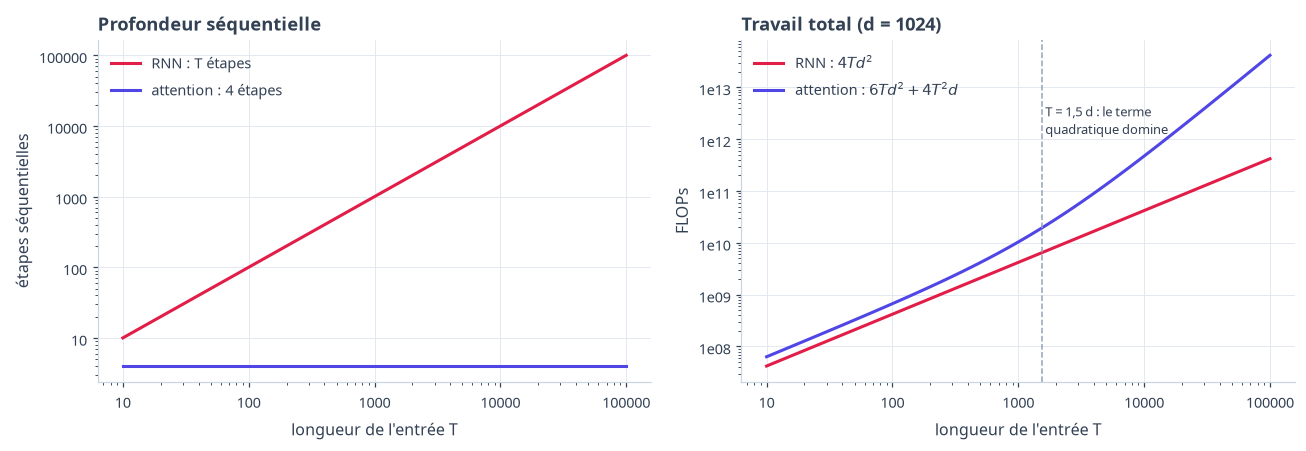

In [9]:
dim = 1024
T_grid = np.logspace(1, 5, 60)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.loglog(T_grid, T_grid, color=ROSE, label="RNN : T étapes")
ax.loglog(T_grid, np.full_like(T_grid, 4), color=INDIGO, label="attention : 4 étapes")
ax.set_xlabel("longueur de l'entrée T"); ax.set_ylabel("étapes séquentielles")
ax.set_title("Profondeur séquentielle"); ax.legend(); m.plain_log_axis(ax); m.plain_log_axis(ax, "y")
ax = axes[1]
w_rnn = T_grid * 4 * dim ** 2
w_att = 6 * T_grid * dim ** 2 + 4 * T_grid ** 2 * dim
ax.loglog(T_grid, w_rnn, color=ROSE, label=r"RNN : $4Td^2$")
ax.loglog(T_grid, w_att, color=INDIGO, label=r"attention : $6Td^2 + 4T^2d$")
ax.axvline(1.5 * dim, color=GRAY, ls="--", lw=1)
ax.text(1.6 * dim, w_rnn.max() * 3, "T = 1,5 d : le terme\nquadratique domine", fontsize=8.5, color=SLATE)
ax.set_xlabel("longueur de l'entrée T"); ax.set_ylabel("FLOPs")
ax.set_title(f"Travail total (d = {dim})"); ax.legend(loc="upper left"); m.plain_log_axis(ax)
m.plain_log_axis(ax, "y", lambda v: f"{v:.0e}".replace("e+", "e"))
plt.tight_layout(); plt.show()

Le transformer échange donc du **travail** contre du **parallélisme** : pour les entrées
courtes, l'attention coûte à peine plus qu'un RNN tout en étant parallélisable ; pour
les très longues entrées ($T \gg d$), son coût quadratique en $T$ devient le principal
problème, ce qui motive les architectures alternatives du cours 2 (SSM, Mamba).

Attention toutefois : le transformer ne supprime le goulot séquentiel **qu'en entrée**.
Un modèle autorégressif génère toujours un token après l'autre. L'inférence se fait donc
en deux temps : le **prefill** (l'entrée est traitée en parallèle, et l'on calcule les
vecteurs clés et valeurs de tous ses tokens) puis le **decode** (un token à la fois).
Le cours 2 mesure ces deux régimes.

> **À retenir.** Le transformer remplace la récurrence par l'attention : chaque token
> accède directement à tous les tokens précédents (fin du goulot d'information), et
> l'entrée se traite en parallèle (fin du goulot séquentiel en entrée).

## 6. Le mécanisme d'attention, pas à pas (section *Attention mechanism*)

**Intuition (l'analogie du livre).** Pour écrire le prochain mot, le modèle consulte les
« pages » que sont les tokens précédents :

- la **requête** $q$ (*query*) représente ce que l'on cherche à l'étape courante ;
- chaque **clé** $k_j$ (*key*) est comme le numéro, l'étiquette d'une page ;
- chaque **valeur** $v_j$ (*value*) est le contenu de cette page.

Le score $q \cdot k_j$ mesure la pertinence de la page $j$ ; on normalise les scores par
une softmax, puis on lit un **mélange** des contenus pondéré par ces poids.

**Formalisation.** Pour une séquence $x \in \mathbb R^{T \times d}$ et des matrices
apprises $W_Q, W_K, W_V \in \mathbb R^{d \times d}$ :
$$Q = xW_Q,\quad K = xW_K,\quad V = xW_V,\qquad
\text{Attention}(Q,K,V) = \operatorname{softmax}\!\Big(\frac{QK^\top}{\sqrt{d}}\Big)V .$$
La ligne $i$ de la matrice $A = \operatorname{softmax}(QK^\top/\sqrt d)$ contient les
poids que le token $i$ accorde à chaque token $j$ ; elle somme à 1.

Construisons un exemple à la main : quatre tokens dont les clés sont presque orthogonales,
et une requête « qui cherche » le troisième.

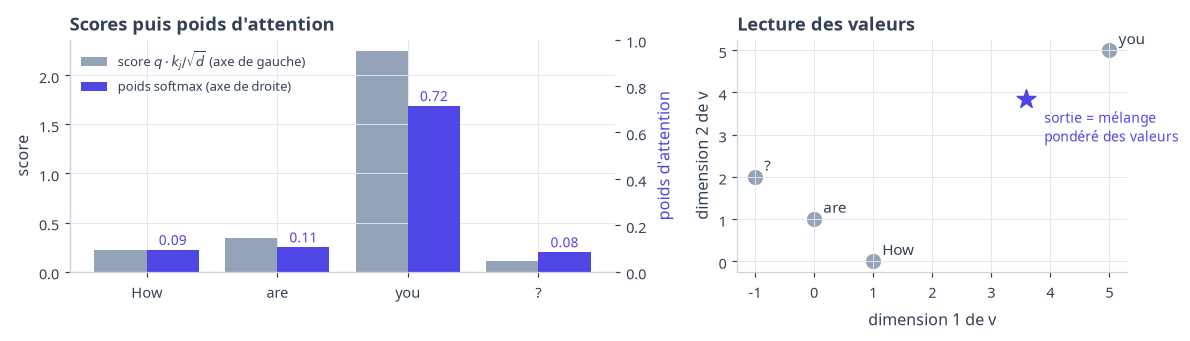

In [10]:
toks = ["How", "are", "you", "?"]
K = np.eye(4) * 1.5                                          # quatre clés orthogonales
V = np.array([[1.0, 0], [0, 1.0], [5.0, 5.0], [-1.0, 2.0]])  # contenu de chaque « page »
q = np.array([[0.2, 0.3, 2.0, 0.1]]) * 1.5                   # la requête ressemble à la clé de « you »
out, w = m.scaled_dot_product_attention(q, K, V)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax = axes[0]
scores = (q @ K.T / np.sqrt(4))[0]
ax.bar(np.arange(4) - 0.2, scores, 0.4, color=GRAY, label=r"score $q\cdot k_j/\sqrt{d}$ (axe de gauche)")
ax.set_ylabel("score")
ax2 = ax.twinx(); ax2.grid(False)
ax2.bar(np.arange(4) + 0.2, w[0], 0.4, color=INDIGO, label="poids softmax (axe de droite)")
ax2.set_ylim(0, 1); ax2.set_ylabel("poids d'attention", color=INDIGO)
for j in range(4):
    ax2.text(j + 0.2, w[0, j] + 0.02, f"{w[0, j]:.2f}", ha="center", fontsize=9, color=INDIGO)
ax.set_xticks(range(4), toks); ax.set_title("Scores puis poids d'attention")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8.5)
ax = axes[1]
ax.scatter(V[:, 0], V[:, 1], s=80, color=GRAY)
for j, t in enumerate(toks):
    ax.annotate(t, V[j], xytext=(6, 4), textcoords="offset points")
ax.scatter(*out[0], s=160, color=INDIGO, marker="*", zorder=3)
ax.annotate("sortie = mélange\npondéré des valeurs", out[0], xytext=(12, -28), textcoords="offset points",
            color=INDIGO, fontsize=9)
ax.set_title("Lecture des valeurs"); ax.set_xlabel("dimension 1 de v"); ax.set_ylabel("dimension 2 de v")
plt.tight_layout(); plt.show()

**Pourquoi diviser par $\sqrt d$ ?** Si les composantes de $q$ et $k$ sont indépendantes,
de moyenne nulle et de variance 1, alors $q \cdot k = \sum_{i=1}^d q_i k_i$ a une variance
$d$. Sans normalisation, les scores grandissent comme $\sqrt d$ et la softmax **sature** :
presque tout le poids va à un seul token, et les gradients s'annulent. Diviser par
$\sqrt d$ ramène la variance à 1. Vérification numérique : entropie moyenne des poids
d'attention sur 64 clés aléatoires (l'entropie maximale vaut $\ln 64 \approx 4{,}16$ nats).

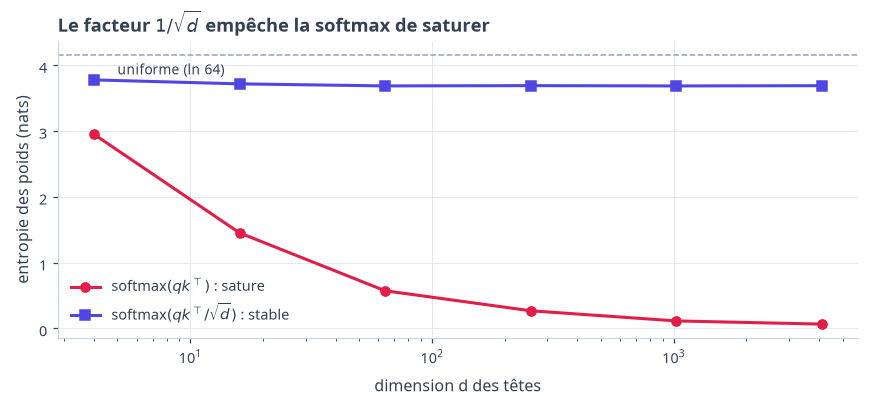

In [11]:
dims = [4, 16, 64, 256, 1024, 4096]
H_raw, H_scaled = [], []
for dd in dims:
    qq = rng.normal(size=(200, dd)); kk = rng.normal(size=(64, dd))
    s = qq @ kk.T
    H_raw.append(np.mean([m.entropy(p) for p in llm.softmax(s)]))
    H_scaled.append(np.mean([m.entropy(p) for p in llm.softmax(s / np.sqrt(dd))]))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogx(dims, H_raw, "o-", color=ROSE, label=r"softmax$(qk^\top)$ : sature")
ax.semilogx(dims, H_scaled, "s-", color=INDIGO, label=r"softmax$(qk^\top/\sqrt{d})$ : stable")
ax.axhline(np.log(64), color=GRAY, ls="--", lw=1); ax.text(5, np.log(64) - 0.3, "uniforme (ln 64)", fontsize=9)
ax.set_xlabel("dimension d des têtes"); ax.set_ylabel("entropie des poids (nats)")
ax.set_title(r"Le facteur $1/\sqrt{d}$ empêche la softmax de saturer"); ax.legend()
plt.tight_layout(); plt.show()

**Le masque causal.** Un modèle de langue ne doit pas « tricher » en regardant les tokens
futurs : on impose $A_{ij} = 0$ pour $j > i$ en mettant les scores correspondants à
$-\infty$ avant la softmax. C'est ce que fait `m.causal_mask`.

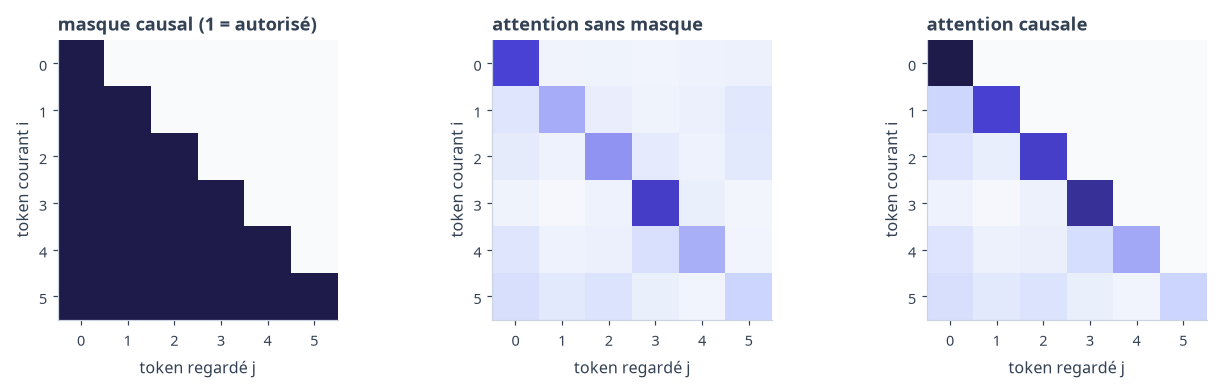

In [12]:
T = 6
xs = rng.normal(size=(T, 8))
_, w_full = m.scaled_dot_product_attention(xs, xs, xs)
_, w_causal = m.scaled_dot_product_attention(xs, xs, xs, m.causal_mask(T))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, mat, title in zip(axes, [m.causal_mask(T).astype(float), w_full, w_causal],
                          ["masque causal (1 = autorisé)", "attention sans masque", "attention causale"]):
    ax.imshow(mat, cmap="aie_seq", vmin=0, vmax=1); ax.grid(False)
    ax.set_title(title); ax.set_xlabel("token regardé j"); ax.set_ylabel("token courant i")
plt.tight_layout(); plt.show()

Chaque nouveau token ajoute sa clé et sa valeur à la mémoire : plus la séquence est longue, plus
il faut calculer et **stocker** de vecteurs $k_j, v_j$. C'est l'une des raisons pour
lesquelles allonger le contexte des transformers est difficile (cours 2, cache KV).

> **À retenir.** L'attention est une **recherche douce** dans une mémoire clé-valeur :
> scores $QK^\top/\sqrt d$, softmax (avec masque causal), puis moyenne pondérée des
> valeurs. Toute l'architecture est différentiable et parallélisable.

## 7. Attention multi-têtes : vérification sur GPT-2 et Qwen2.5

En pratique, l'attention est **multi-têtes** : les vecteurs $Q, K, V$ de dimension $d$
sont découpés en $h$ morceaux de dimension $d_h = d/h$, chaque tête calcule sa propre
attention, puis les sorties sont concaténées et passées dans une **projection de
sortie** $W_O$. Pour Llama 2-7B : $d = 4096$, $h = 32$, donc $d_h = 128$. Plusieurs têtes
permettent de suivre en parallèle plusieurs types de relations (syntaxe, coréférence,
position...).

Notre implémentation `m.multi_head_attention` tient en une dizaine de lignes. Est-elle
**exactement** celle d'un vrai modèle ? Prenons la première couche de GPT-2 : on capture
(par des *hooks* PyTorch) l'entrée normalisée de l'attention et sa sortie, puis on refait
le calcul en numpy avec les poids du modèle. Dans GPT-2, $W_Q, W_K, W_V$ sont stockées
côte à côte dans une seule matrice `c_attn` de taille $768 \times 2304$.

In [13]:
gtok, gpt2 = m.load_eager("gpt2")
sentence = "The animal didn't cross the street because it was too tired."
inputs = gtok(sentence, return_tensors="pt")
captured = {}
block0 = gpt2.transformer.h[0]
hooks = [block0.ln_1.register_forward_hook(lambda mod, i, o: captured.__setitem__("x", o)),
         block0.attn.register_forward_hook(lambda mod, i, o: captured.__setitem__("out", o[0]))]
with torch.no_grad():
    ref = gpt2(**inputs, output_attentions=True)
for h in hooks:
    h.remove()

x0 = captured["x"][0].numpy()
W, b = block0.attn.c_attn.weight.detach().numpy(), block0.attn.c_attn.bias.detach().numpy()
D = 768
out_np, w_np = m.multi_head_attention(
    x0, W[:, :D], W[:, D:2 * D], W[:, 2 * D:], block0.attn.c_proj.weight.detach().numpy(), n_heads=12,
    bq=b[:D], bk=b[D:2 * D], bv=b[2 * D:], bo=block0.attn.c_proj.bias.detach().numpy())
print(f"séquence : {x0.shape[0]} tokens, d = {D}, 12 têtes de dimension {D // 12}")
print(f"écart max. sur les poids d'attention : {np.abs(w_np - ref.attentions[0][0].numpy()).max():.1e}")
print(f"écart max. sur la sortie de la couche : {np.abs(out_np - captured['out'][0].numpy()).max():.1e}")

séquence : 13 tokens, d = 768, 12 têtes de dimension 64
écart max. sur les poids d'attention : 3.4e-07
écart max. sur la sortie de la couche : 4.8e-06


Les écarts sont de l'ordre de $10^{-6}$ : la précision du float32. Notre formule est
bien celle de GPT-2.

**Et un modèle récent ?** Qwen2.5-0.5B ajoute deux ingrédients devenus standards :

- **RoPE** (*rotary position embeddings*) : au lieu d'ajouter un vecteur de position à
  l'entrée (comme GPT-2), on **fait tourner** $q$ et $k$ d'un angle proportionnel à leur
  position. Le produit scalaire $\langle R_m q, R_n k\rangle$ ne dépend alors que de
  l'écart $m - n$ : le modèle raisonne en positions relatives ;
- **GQA** (*grouped-query attention*) : 14 têtes de requêtes mais seulement 2 têtes de
  clés et de valeurs, partagées par groupes de 7. Cela divise par 7 la taille du cache KV
  (cours 2).

On rejoue la première couche de Qwen2.5 avec `m.rope` et une répétition des têtes KV.

In [14]:
qtok, qwen = m.load_eager(llm.SMALL)
q_inputs = qtok(sentence, return_tensors="pt")
captured = {}
layer0 = qwen.model.layers[0]
hooks = [layer0.input_layernorm.register_forward_hook(lambda mod, i, o: captured.__setitem__("x", o)),
         layer0.self_attn.register_forward_hook(lambda mod, i, o: captured.__setitem__("out", o[0]))]
with torch.no_grad():
    q_ref = qwen(**q_inputs, output_attentions=True)
for h in hooks:
    h.remove()

sa, cfg = layer0.self_attn, qwen.config
xq = captured["x"][0].numpy(); Tq = xq.shape[0]
lin = lambda layer: xq @ layer.weight.detach().numpy().T + (layer.bias.detach().numpy() if layer.bias is not None else 0)
Qh = m.split_heads(lin(sa.q_proj), cfg.num_attention_heads)       # (14, T, 64)
Kh = m.split_heads(lin(sa.k_proj), cfg.num_key_value_heads)       # (2, T, 64)
Vh = m.split_heads(lin(sa.v_proj), cfg.num_key_value_heads)
pos = np.arange(Tq)
theta = getattr(cfg, "rope_theta", None) or cfg.rope_parameters["rope_theta"]
Qh, Kh = m.rope(Qh, pos, theta), m.rope(Kh, pos, theta)
group = cfg.num_attention_heads // cfg.num_key_value_heads
Kh, Vh = np.repeat(Kh, group, axis=0), np.repeat(Vh, group, axis=0)  # GQA : chaque tête KV sert 7 requêtes
o_heads, wq = m.scaled_dot_product_attention(Qh, Kh, Vh, m.causal_mask(Tq))
out_q = m.merge_heads(o_heads) @ sa.o_proj.weight.detach().numpy().T
print(f"Qwen2.5-0.5B : {cfg.num_attention_heads} têtes de requêtes, {cfg.num_key_value_heads} têtes KV, "
      f"RoPE theta = {theta:.0e}")
print(f"écart max. sur les poids d'attention : {np.abs(wq - q_ref.attentions[0][0].numpy()).max():.1e}")
print(f"écart max. sur la sortie de la couche : {np.abs(out_q - captured['out'][0].numpy()).max():.1e}")

Qwen2.5-0.5B : 14 têtes de requêtes, 2 têtes KV, RoPE theta = 1e+06
écart max. sur les poids d'attention : 3.1e-05
écart max. sur la sortie de la couche : 6.4e-07


Là encore, accord à la précision machine. Visualisons la propriété clé de RoPE : avec
une même paire de vecteurs $(q, k)$ placée à toutes les positions, le score ne dépend
que de l'écart $m - n$ (diagonales constantes), et il décroît en moyenne avec la
distance.

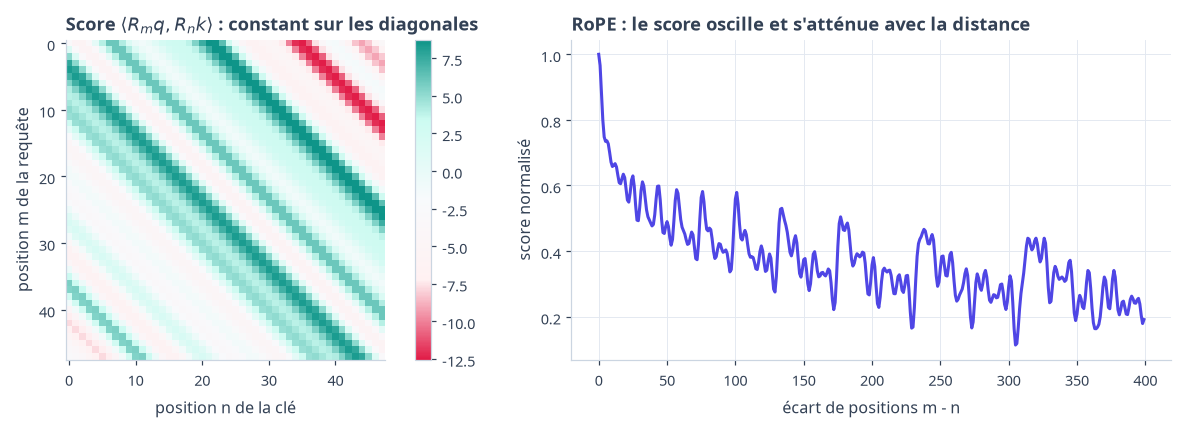

In [15]:
qv, kv = rng.normal(size=(2, 64))
P = 48
Rq = m.rope(np.tile(qv, (P, 1)), np.arange(P), 10000.0)
Rk = m.rope(np.tile(kv, (P, 1)), np.arange(P), 10000.0)
S = Rq @ Rk.T
dist = np.arange(0, 400)
qq = np.ones(64); kk = np.ones(64)  # vecteurs alignés : on suit la décroissance avec l'écart
decay = [(m.rope(qq[None], [dd]) @ m.rope(kk[None], [0]).T).item() / 64 for dd in dist]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]; im = ax.imshow(S, cmap="aie_div"); ax.grid(False)
ax.set_xlabel("position n de la clé"); ax.set_ylabel("position m de la requête")
ax.set_title(r"Score $\langle R_m q, R_n k\rangle$ : constant sur les diagonales"); plt.colorbar(im, ax=ax)
ax = axes[1]; ax.plot(dist, decay, color=INDIGO)
ax.set_xlabel("écart de positions m - n"); ax.set_ylabel("score normalisé")
ax.set_title("RoPE : le score oscille et s'atténue avec la distance")
plt.tight_layout(); plt.show()

> **À retenir.** Une couche d'attention réelle, c'est exactement la formule
> $\operatorname{softmax}(QK^\top/\sqrt{d_h})V$ appliquée par tête, plus des raffinements
> d'ingénierie : RoPE pour les positions relatives, GQA pour économiser la mémoire.

## 8. Ce que regardent les têtes : cartes d'attention réelles

Chaque tête apprend son propre motif. Affichons les 12 têtes d'une couche intermédiaire
de GPT-2 sur notre phrase.

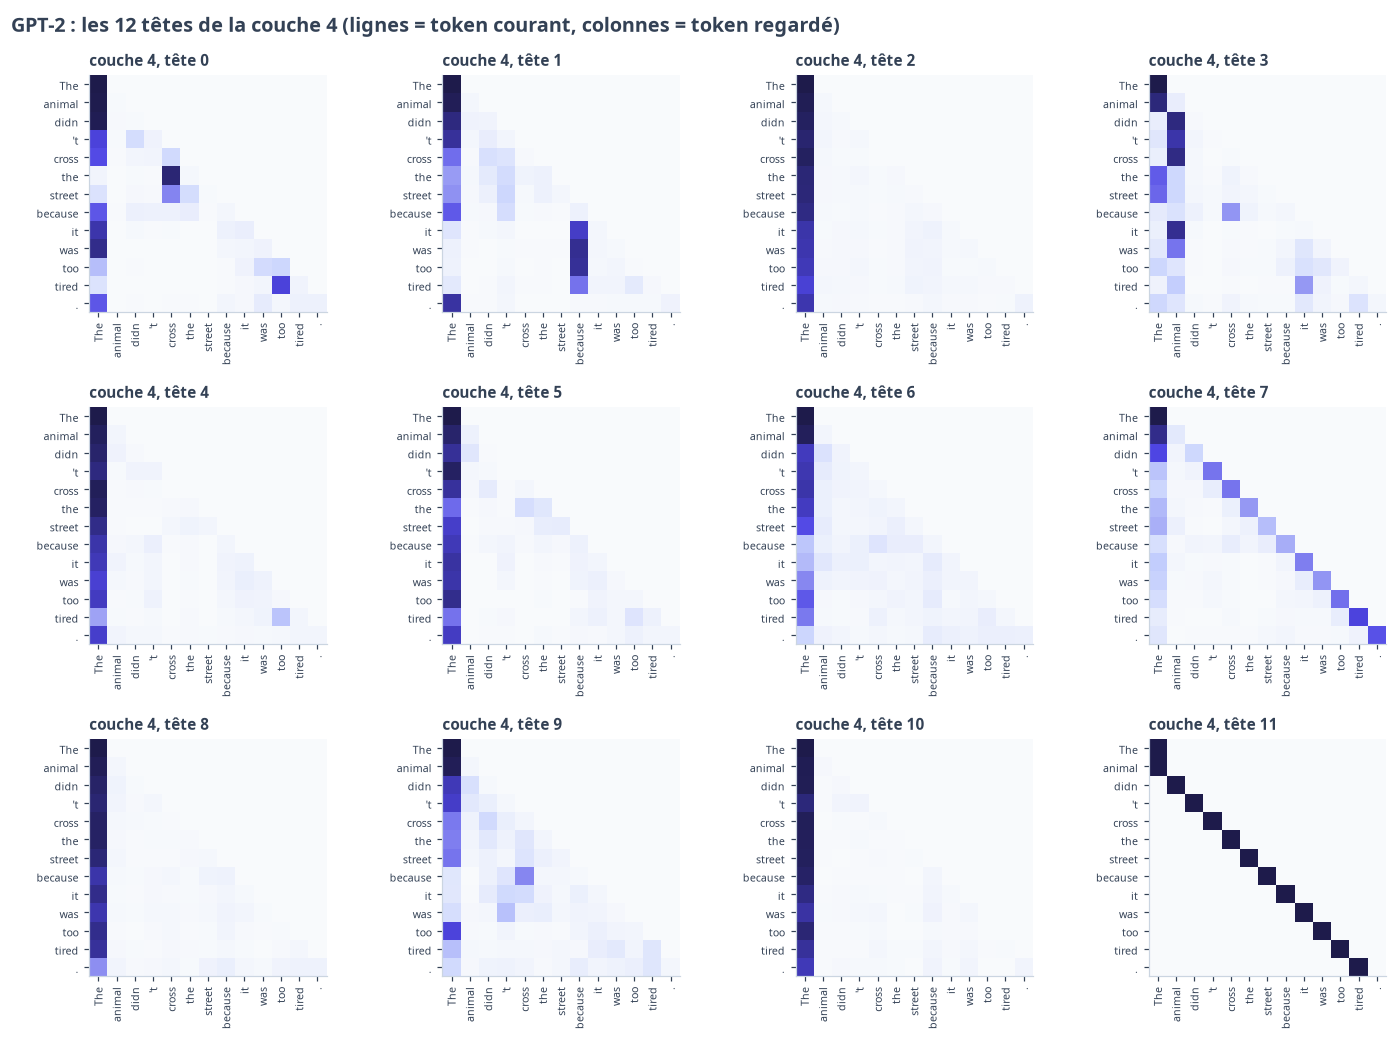

In [16]:
tokens_g, att = m.attention_maps(sentence, "gpt2")   # att : (12 couches, 12 têtes, T, T)
labels = [t.strip() or "_" for t in tokens_g]
layer = 4
fig, axes = plt.subplots(3, 4, figsize=(13, 9.6))
for hh, ax in enumerate(axes.flat):
    ax.imshow(att[layer, hh], cmap="aie_seq", vmin=0, vmax=1); ax.grid(False)
    ax.set_title(f"couche {layer}, tête {hh}", fontsize=10)
    ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=7)
    ax.set_yticks(range(len(labels)), labels, fontsize=7)
finish(fig, f"GPT-2 : les 12 têtes de la couche {layer} (lignes = token courant, colonnes = token regardé)")
plt.show()

On distingue des motifs typiques : des têtes qui regardent le **token précédent**
(diagonale décalée), d'autres qui concentrent presque tout le poids sur le **premier
token** (un « puits d'attention », *attention sink*, qui sert de position « neutre »
quand rien n'est pertinent), d'autres encore plus diffuses.

Pour aller au-delà de l'œil, calculons pour toutes les têtes deux scores :
le poids moyen sur le token précédent, $\frac{1}{T-1}\sum_i A_{i,i-1}$, et le poids moyen
sur le premier token.

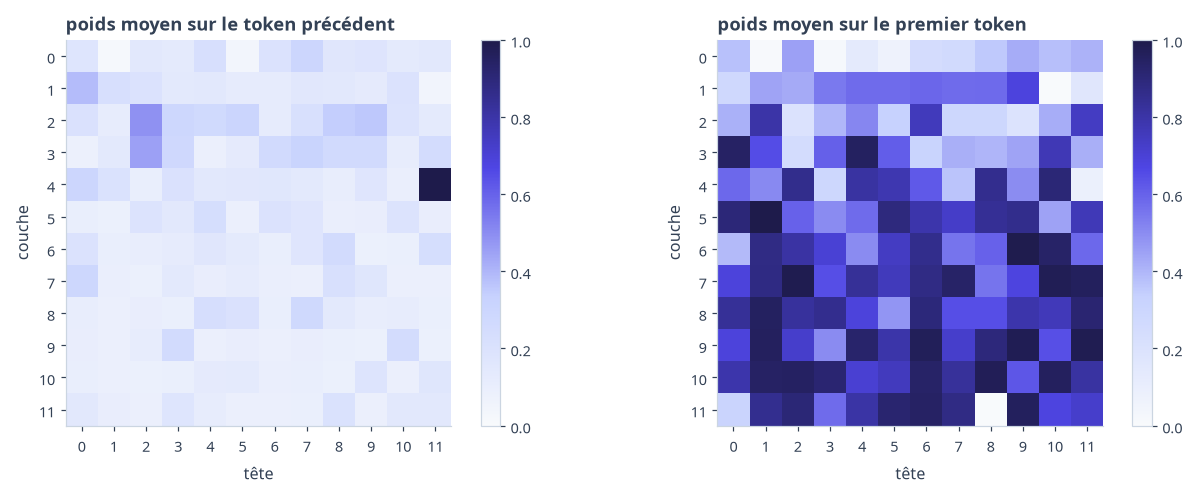

tête « token précédent » la plus nette : couche 4, tête 11 (score 1.00)
part des têtes dont plus de la moitié du poids va au premier token : 72%


In [17]:
Tn = att.shape[-1]
prev_score = np.array([[np.mean([att[l, hh, i, i - 1] for i in range(1, Tn)]) for hh in range(12)]
                       for l in range(12)])
first_score = att[:, :, 1:, 0].mean(-1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, sc, title in zip(axes, [prev_score, first_score],
                         ["poids moyen sur le token précédent", "poids moyen sur le premier token"]):
    im = ax.imshow(sc, cmap="aie_seq", vmin=0, vmax=1); ax.grid(False)
    ax.set_xlabel("tête"); ax.set_ylabel("couche"); ax.set_title(title)
    ax.set_xticks(range(12)); ax.set_yticks(range(12))
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()
best_prev = np.unravel_index(prev_score.argmax(), prev_score.shape)
print(f"tête « token précédent » la plus nette : couche {best_prev[0]}, tête {best_prev[1]} "
      f"(score {prev_score.max():.2f})")
print(f"part des têtes dont plus de la moitié du poids va au premier token : {(first_score > 0.5).mean():.0%}")

**Les têtes d'induction.** Un mécanisme célèbre (Olsson et al., 2022) explique une partie
de l'apprentissage en contexte : quand le motif « A B ... A » apparaît, une tête
d'induction regarde le token qui **suivait** le précédent A (donc B) pour prédire B.
Expérience classique : une suite de tokens aléatoires répétée deux fois. Dans la seconde
moitié, une tête d'induction en position $i$ regarde la position $i - L + 1$ ($L$ = longueur
de la suite). On mesure aussi la log-probabilité des tokens : imprévisibles la première
fois, ils deviennent faciles à prédire la seconde.

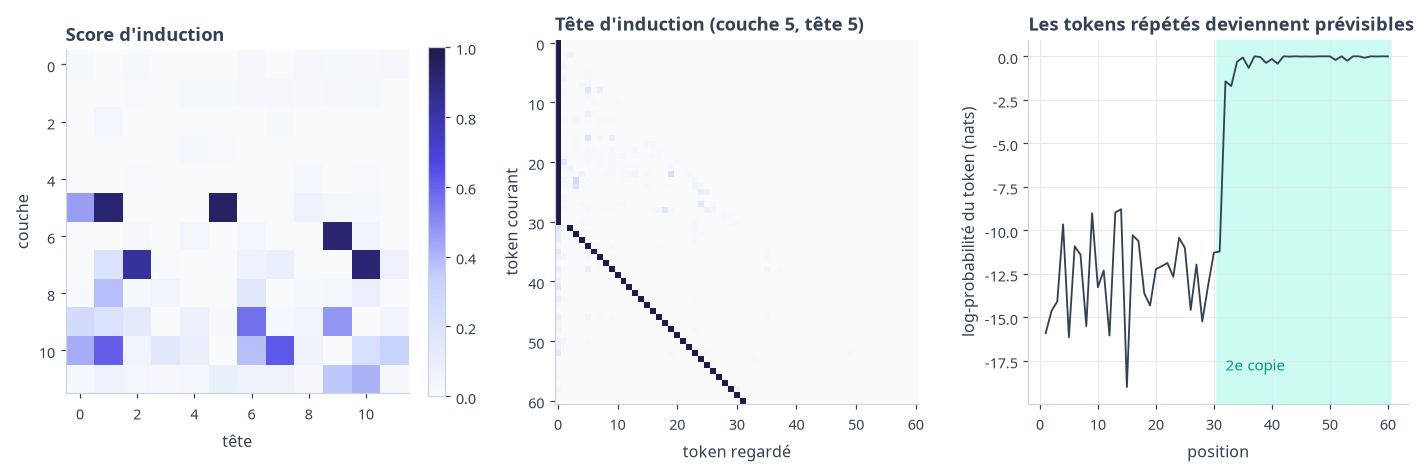

logprob moyenne : 1re copie -12.7 nats, 2e copie -0.6 nats


In [18]:
rs = np.random.default_rng(3)
Lseq = 30
rand_ids = rs.integers(1000, 30000, Lseq).tolist()
ids = torch.tensor([[gtok.bos_token_id] + rand_ids + rand_ids])
with torch.no_grad():
    o = gpt2(ids, output_attentions=True)
A = torch.stack(o.attentions)[:, 0].numpy()            # (12, 12, 2L+1, 2L+1)
lp = torch.log_softmax(o.logits[0, :-1], -1)[torch.arange(2 * Lseq), ids[0, 1:]].numpy()
idx = np.arange(Lseq + 1, 2 * Lseq + 1)                 # positions de la seconde copie
induction = A[:, :, idx, idx - Lseq + 1].mean(-1)       # poids sur le token « suivant » la 1re occurrence
bl, bh = np.unravel_index(induction.argmax(), induction.shape)

fig = plt.figure(figsize=(13, 4.4))
ax1 = fig.add_subplot(1, 3, 1)
im = ax1.imshow(induction, cmap="aie_seq", vmin=0, vmax=1); ax1.grid(False)
ax1.set_xlabel("tête"); ax1.set_ylabel("couche"); ax1.set_title("Score d'induction")
plt.colorbar(im, ax=ax1, fraction=0.046)
ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(A[bl, bh], cmap="aie_seq", vmin=0, vmax=0.6); ax2.grid(False)
ax2.set_title(f"Tête d'induction (couche {bl}, tête {bh})")
ax2.set_xlabel("token regardé"); ax2.set_ylabel("token courant")
ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(np.arange(1, 2 * Lseq + 1), lp, color=SLATE, lw=1.2)
ax3.axvspan(Lseq + 0.5, 2 * Lseq + 0.5, color=LIGHT[TEAL])
ax3.text(Lseq + 2, lp.min() * 0.95, "2e copie", color=TEAL)
ax3.set_xlabel("position"); ax3.set_ylabel("log-probabilité du token (nats)")
ax3.set_title("Les tokens répétés deviennent prévisibles")
plt.tight_layout(); plt.show()
print(f"logprob moyenne : 1re copie {lp[:Lseq].mean():.1f} nats, 2e copie {lp[Lseq:].mean():.1f} nats")

La diagonale décalée de la tête d'induction et l'effondrement de la perte sur la
seconde copie sont deux faces du même phénomène : le modèle **copie** depuis son
contexte, une forme élémentaire d'apprentissage en contexte (chapitre 1, et chapitre 5
pour le *few-shot*).

> **À retenir.** Les têtes d'attention se spécialisent (token précédent, puits
> d'attention, induction...). Ces motifs s'observent directement dans les poids, ce qui
> fait de l'attention l'un des rares points d'entrée concrets dans l'interprétabilité
> des modèles.

## 9. Le bloc transformer (section *Transformer block*)

Un modèle de langue transformer empile $L$ **blocs** identiques (le « nombre de
couches »). Chaque bloc contient :

- un **module d'attention** : quatre matrices $W_Q, W_K, W_V, W_O$ ;
- un **module MLP** (ou *feedforward*) : des couches linéaires séparées par une
  non-linéarité, qui passent de $d$ à $d_{ff}$ (souvent $\approx 4d$) puis reviennent à $d$ ;
- des **normalisations** (LayerNorm ou RMSNorm) et des **connexions résiduelles**
  $x \leftarrow x + \text{module}(\text{norm}(x))$, qui stabilisent l'entraînement profond.

Avant les blocs, un module de **plongement** (*embedding*) transforme chaque token (et,
pour GPT-2, chaque position) en vecteur ; après eux, une couche de **sortie**
(*unembedding*, ou tête du modèle) produit un logit par token du vocabulaire.

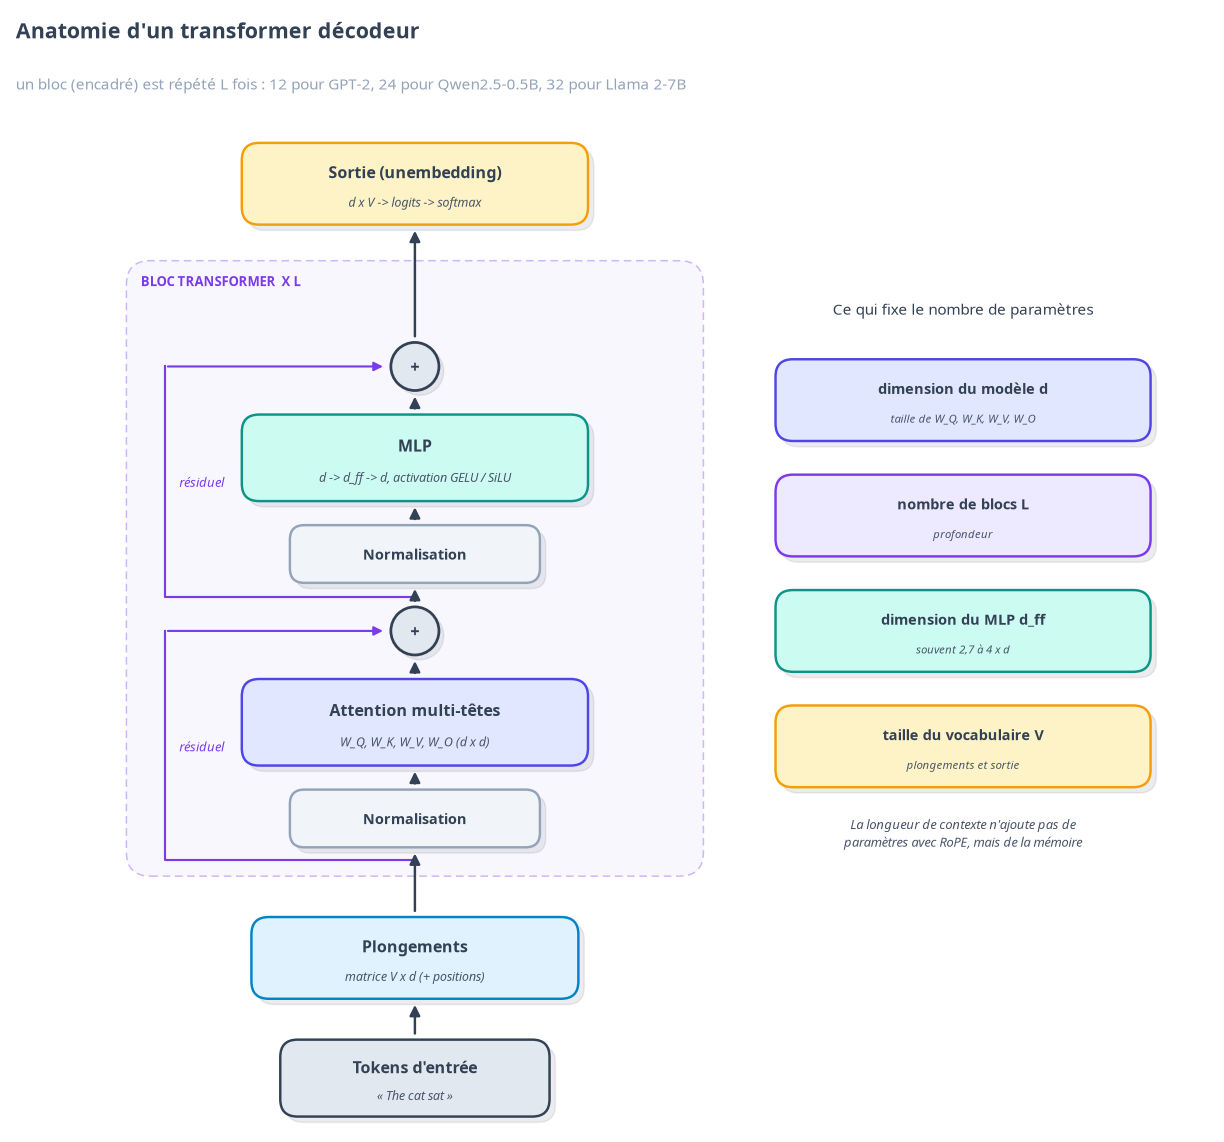

In [19]:
d = Diagram(12.5, 10.7, title="Anatomie d'un transformer décodeur",
            subtitle="un bloc (encadré) est répété L fois : 12 pour GPT-2, 24 pour Qwen2.5-0.5B, 32 pour Llama 2-7B")
cx = 4.2
d.box("tok", cx, 0.55, "Tokens d'entrée", sub="« The cat sat »", color=SLATE, w=2.8, h=0.8)
d.box("emb", cx, 1.8, "Plongements", sub="matrice V x d (+ positions)", color=SKY, w=3.4, h=0.85)
d.group(1.2, 2.65, 7.2, 9.05, "bloc transformer  x L", color=VIOLET)
d.box("n1", cx, 3.25, "Normalisation", color=GRAY, w=2.6, h=0.6, fontsize=9.5)
d.box("att", cx, 4.25, "Attention multi-têtes", sub="W_Q, W_K, W_V, W_O (d x d)", color=INDIGO, w=3.6, h=0.9)
d.box("r1", cx, 5.2, "+", color=SLATE, kind="circle", w=0.5)
d.box("n2", cx, 6.0, "Normalisation", color=GRAY, w=2.6, h=0.6, fontsize=9.5)
d.box("mlp", cx, 7.0, "MLP", sub="d -> d_ff -> d, activation GELU / SiLU", color=TEAL, w=3.6, h=0.9)
d.box("r2", cx, 7.95, "+", color=SLATE, kind="circle", w=0.5)
d.box("out", cx, 9.85, "Sortie (unembedding)", sub="d x V -> logits -> softmax", color=AMBER, w=3.6, h=0.85)
for a, b in [("tok", "emb"), ("emb", "n1"), ("n1", "att"), ("att", "r1"), ("r1", "n2"), ("n2", "mlp"),
             ("mlp", "r2"), ("r2", "out")]:
    d.arrow(a, b)
d.line([(cx, 2.82), (1.6, 2.82), (1.6, 5.2), (cx - 0.3, 5.2)], color=VIOLET, style="solid", lw=1.4)
d.line([(cx, 5.55), (1.6, 5.55), (1.6, 7.95), (cx - 0.3, 7.95)], color=VIOLET, style="solid", lw=1.4)
d.note(1.75, 4.0, "résiduel", color=VIOLET, fontsize=8.5, ha="left")
d.note(1.75, 6.75, "résiduel", color=VIOLET, fontsize=8.5, ha="left")
# panneau de droite : ce qui fixe la taille
d.box("k1", 9.9, 7.6, "dimension du modèle d", sub="taille de W_Q, W_K, W_V, W_O", color=INDIGO, w=3.9, h=0.85,
      fontsize=9.5)
d.box("k2", 9.9, 6.4, "nombre de blocs L", sub="profondeur", color=VIOLET, w=3.9, h=0.85, fontsize=9.5)
d.box("k3", 9.9, 5.2, "dimension du MLP d_ff", sub="souvent 2,7 à 4 x d", color=TEAL, w=3.9, h=0.85, fontsize=9.5)
d.box("k4", 9.9, 4.0, "taille du vocabulaire V", sub="plongements et sortie", color=AMBER, w=3.9, h=0.85,
      fontsize=9.5)
d.note(9.9, 8.55, "Ce qui fixe le nombre de paramètres", color=SLATE, fontsize=10, style="normal")
d.note(9.9, 3.1, "La longueur de contexte n'ajoute pas de\nparamètres avec RoPE, mais de la mémoire",
       fontsize=8.5)
d.show()

**Les fonctions d'activation.** Le MLP a seulement besoin d'une non-linéarité pour
casser la linéarité des couches successives. Le livre note que les fonctions
sophistiquées n'ont pas fait mieux que des fonctions simples et rapides à calculer :
ReLU $\max(0, x)$, GELU (GPT-2, GPT-3) $x\,\Phi(x)$, ou SiLU $x\,\sigma(x)$ (utilisée,
avec une porte multiplicative, dans les MLP « SwiGLU » de Llama et Qwen).

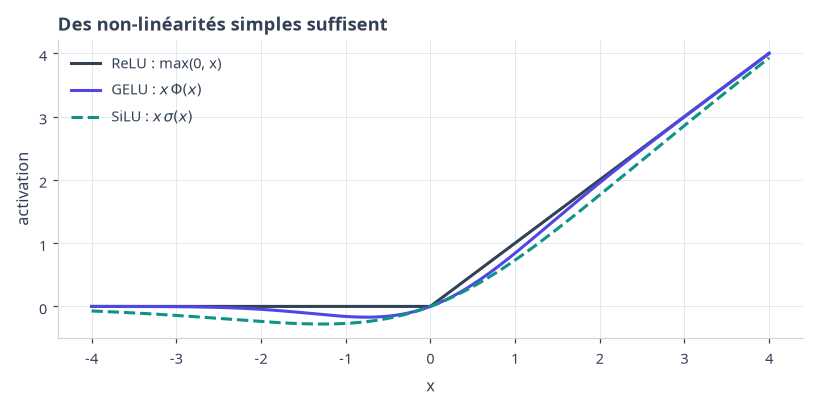

In [20]:
from scipy.stats import norm as _norm

xx = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(xx, np.maximum(0, xx), color=SLATE, label="ReLU : max(0, x)")
ax.plot(xx, xx * _norm.cdf(xx), color=INDIGO, label=r"GELU : $x\,\Phi(x)$")
ax.plot(xx, xx * m.sigmoid(xx), color=TEAL, ls="--", label=r"SiLU : $x\,\sigma(x)$")
ax.set_xlabel("x"); ax.set_ylabel("activation"); ax.legend()
ax.set_title("Des non-linéarités simples suffisent")
plt.tight_layout(); plt.show()

**Vérification des dimensions sur GPT-2.** Parcourons les tenseurs d'un bloc : les
formes retrouvent exactement le schéma (d = 768, d_ff = 3072 = 4d).

In [21]:
shapes = pd.DataFrame([(n.replace("transformer.h.0.", ""), tuple(p.shape), p.numel())
                       for n, p in gpt2.named_parameters() if n.startswith("transformer.h.0.")],
                      columns=["tenseur du bloc 0", "forme", "paramètres"])
print(f"total par bloc : {shapes['paramètres'].sum():,} paramètres".replace(",", " "))
shapes

total par bloc : 7 087 872 paramètres


,tenseur du bloc 0,forme,paramètres
0,ln_1.weight,"(768,)",768
1,ln_1.bias,"(768,)",768
2,attn.c_attn.weight,"(768, 2304)",1769472
3,attn.c_attn.bias,"(2304,)",2304
4,attn.c_proj.weight,"(768, 768)",589824
5,attn.c_proj.bias,"(768,)",768
6,ln_2.weight,"(768,)",768
7,ln_2.bias,"(768,)",768
8,mlp.c_fc.weight,"(768, 3072)",2359296
9,mlp.c_fc.bias,"(3072,)",3072


Environ 7,1 millions de paramètres par bloc, dont un tiers pour l'attention
($4d^2$) et deux tiers pour le MLP ($2 \cdot d \cdot 4d = 8d^2$). Le cours 2 généralise ce
comptage à n'importe quelle configuration (Llama, Qwen, Mixtral) et en tire mémoire et
coût d'entraînement.

## Synthèse

- **Données.** Un modèle reflète la distribution de ses données. Le web est dominé par
  l'anglais (46 % de Common Crawl) ; des langues parlées par des centaines de millions de
  personnes y sont 50 à 200 fois sous-représentées.
- **Tokens par langue.** Le même contenu peut coûter de 1 à plus de 10 fois plus de
  tokens selon la langue et le tokenizer, ce qui se répercute sur le coût, la latence et
  le contexte utile. Les grands vocabulaires multilingues réduisent l'écart.
- **Domaines.** Les bits par caractère sur un échantillon de textes révèlent si un
  domaine est couvert ; les domaines rares (biologie, médecine) justifient des modèles
  spécialisés.
- **Transformer.** L'attention supprime le goulot d'information du seq2seq et permet de
  traiter l'entrée en parallèle ; la génération reste séquentielle (prefill puis decode).
- **Attention.** $\operatorname{softmax}(QK^\top/\sqrt{d})V$, avec masque causal et
  plusieurs têtes. Notre implémentation numpy reproduit à $10^{-6}$ près GPT-2 et
  Qwen2.5 (RoPE, GQA compris), et les cartes réelles montrent des têtes spécialisées
  (token précédent, induction).

**Liens.** Le cours 2 chiffre la taille, la mémoire et le coût de ces architectures et
présente leurs alternatives (SSM, Mamba) ; le chapitre 3 formalise perplexité et bits
par caractère ; le chapitre 7 revient sur la mémoire de l'attention, et le chapitre 9 sur
l'optimisation du prefill et du decode.

In [22]:
m.load_eager.cache_clear()
llm.free_gpu()